# 6. Season-long projections for draft prep

Weekly projections help set a lineup. Drafts need a different question: **how many points per game will a player score
next season?** Notebook 4 found three things that should help: players age on position-specific curves, touchdown rates
regress, and volume carries over. This notebook builds a model on them.

* One row per player-season with 6+ games and 5+ PPR per game, 2012-2025 (snap counts start in 2012).
* Target: the same player's PPR per game the following season (4+ games).
* Train on seasons 2012-2021 → validate predicting 2023 from 2022 → test predicting 2024 and 2025.

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from fantasy.features import TARGET, model_sample
from fantasy.evaluate import score_table, pairwise_accuracy
from fantasy import plots as P

P.use_style()
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
from scipy.stats import spearmanr
from sklearn.ensemble import HistGradientBoostingRegressor
from fantasy.season import SEASON_FEATURES, fit_season_model, predict, season_pairs, season_table

In [2]:
st = season_table(range(2011, 2027))
pairs = season_pairs(st[st.season <= 2025])
labeled = pairs[pairs.games_next >= 4]
print(f"{len(pairs):,} qualifying player-seasons; {len(labeled):,} have a next season with 4+ games "
      f"({len(labeled) / len(pairs[pairs.season <= 2024]):.0%} of those that could)")
labeled[["name", "position", "season", "age", "games", "ppg", "ppg_prev", "touches_pg", "td_pg", "ppg_next"]].sample(5, random_state=2)

3,717 qualifying player-seasons; 2,955 have a next season with 4+ games (85% of those that could)


,name,position,season,age,games,ppg,ppg_prev,touches_pg,td_pg,ppg_next
677,Marshawn Lynch,RB,2012,26.363,16,16.850,16.240,21.125,0.750,17.206
6395,Justice Hill,RB,2023,25.796,16,6.831,2.800,7.000,0.250,8.473
3360,Travis Kelce,TE,2021,31.907,16,16.425,20.851,5.875,0.625,18.606
3997,Allen Robinson,WR,2018,25.021,13,11.792,2.700,4.308,0.308,15.931
705,Kevin Kolb,QB,2011,27.020,9,10.967,10.967,1.889,0.000,14.127


## Baselines vs. models

* **Same as last season**: the default way people anchor.
* **Weighted**: 70% last season + 30% the season before.
* **Ridge**: per-game production, the season before, volume (targets, carries, touches, target share, snap share,
  pass attempts), touchdowns per game, games played, and a separate age curve per position.
* **Gradient boosting**: same features, free to find interactions.

Scores: MAE in points per game, and **rank correlation within position** (does the model order the RBs right?),
which is what a draft board needs.

In [3]:
train = labeled[labeled.season <= 2021]
val = labeled[labeled.season == 2022]
test = labeled[labeled.season.isin([2023, 2024])]

ridge = fit_season_model(train)
hgb = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.03, max_depth=3, min_samples_leaf=40, random_state=0)
hgb.fit(train[SEASON_FEATURES].fillna(0), train.ppg_next)

def add_preds(d):
    return d.assign(same=d.ppg, weighted=0.7 * d.ppg + 0.3 * d.ppg_prev,
                    ridge=predict(ridge, d), hgb=hgb.predict(d[SEASON_FEATURES].fillna(0)))

NAMES = {"same": "Same as last season", "weighted": "Weighted 70/30", "ridge": "Ridge", "hgb": "Gradient boosting"}
def season_scores(d):
    out = {}
    for col, name in NAMES.items():
        rank = np.mean([spearmanr(g[col], g.ppg_next).statistic for _, g in d.groupby(["season", "position"])])
        out[name] = {"MAE": (d[col] - d.ppg_next).abs().mean(), "r": d[col].corr(d.ppg_next), "rank corr. in position": rank}
    return pd.DataFrame(out).T

val, test = add_preds(val), add_preds(test)
display(season_scores(val).round(3).style.set_caption("Validation: 2022 → 2023"))
season_test = season_scores(test)
season_test.round(3)

,MAE,r,rank corr. in position
Same as last season,3.235000,0.734000,0.631000
Weighted 70/30,3.109000,0.740000,0.662000
Ridge,2.867000,0.757000,0.670000
Gradient boosting,2.790000,0.768000,0.692000


,MAE,r,rank corr. in position
Same as last season,3.263,0.699,0.614
Weighted 70/30,3.162,0.712,0.628
Ridge,2.835,0.756,0.677
Gradient boosting,2.841,0.750,0.656


Gradient boosting edges ridge on validation, ridge edges it on test; they're effectively tied. Ridge is the pick:
simpler, and its age curves can be read directly. Either way, both cut the error of "same as last season" by about 13%.

PosixPath('/home/user/nfl-historic-analysis/reports/figures/14_season_model.png')

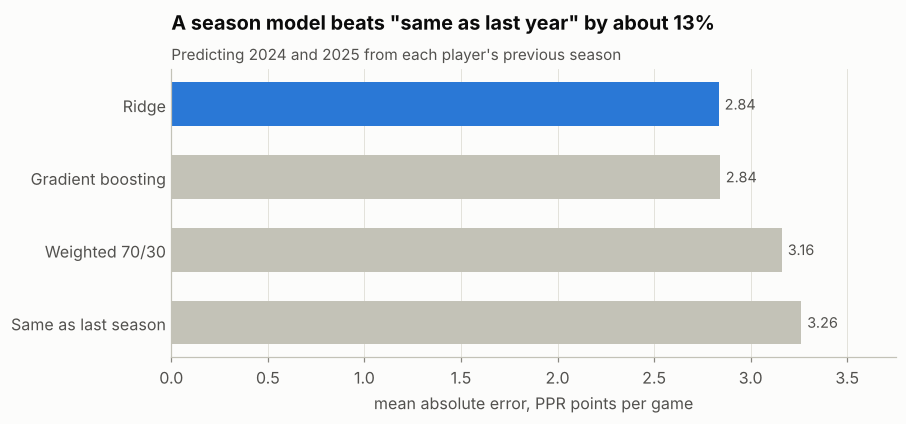

In [4]:
res = season_test["MAE"].sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8.5, 3.4))
y = np.arange(len(res))
ax.barh(y, res.values, height=0.6, color=[P.BLUE if n == "Ridge" else P.GREY for n in res.index])
for yi, v in zip(y, res.values):
    ax.text(v + 0.03, yi, f"{v:.2f}", va="center", color=P.INK_2, fontsize=9.5)
ax.set_yticks(y, res.index)
ax.tick_params(axis="y", length=0)
ax.set_xlim(0, res.max() * 1.15)
ax.grid(axis="y", visible=False)
ax.set_xlabel("mean absolute error, PPR points per game")
ax.set_title("A season model beats \"same as last year\" by about 13%", pad=26)
P.subtitle(ax, "Predicting 2024 and 2025 from each player's previous season")
P.save(fig, "14_season_model")

## Where the model disagrees with last season

The biggest gaps between "same as last season" and the model on the test seasons, and what actually happened:

In [5]:
test["model_change"] = test.ridge - test.ppg
cols = ["name", "position", "season", "age", "ppg", "td_pg", "ridge", "ppg_next"]
print("Model expected a drop:")
display(test.nsmallest(8, "model_change")[cols].round(2))
print("Model expected a rise:")
test.nlargest(8, "model_change")[cols].round(2)

Model expected a drop:


,name,position,season,age,ppg,td_pg,ridge,ppg_next
7965,Kyren Williams,RB,2023,23.01,21.25,1.25,14.40,17.01
4178,Raheem Mostert,RB,2023,31.39,17.85,1.40,11.82,5.45
5671,Chris Godwin Jr.,WR,2024,28.51,19.69,0.71,14.16,9.22
4808,Derrick Henry,RB,2024,30.66,19.79,1.06,14.58,16.44
3193,Keenan Allen,WR,2023,31.35,21.45,0.54,16.36,12.29
6306,Saquon Barkley,RB,2024,27.56,22.21,0.94,17.41,14.52
5149,Christian McCaffrey,RB,2023,27.23,24.46,1.31,19.80,11.95
5203,Kendrick Bourne,WR,2023,28.08,12.50,0.50,8.21,5.42


Model expected a rise:


,name,position,season,age,ppg,td_pg,ridge,ppg_next
8313,C.J. Stroud,QB,2024,22.91,12.96,0.00,15.98,14.90
7365,Rashod Bateman,WR,2023,23.76,5.10,0.07,7.48,10.91
8041,Dontayvion Wicks,WR,2024,23.21,6.50,0.29,8.75,5.83
8307,Bryce Young,QB,2023,22.10,9.77,0.00,11.97,13.93
8430,Braelon Allen,RB,2024,20.62,5.01,0.18,7.16,3.82
7254,Jerry Jeudy,WR,2023,24.36,8.86,0.12,11.00,14.17
8088,Jaxon Smith-Njigba,WR,2023,21.54,8.81,0.24,10.81,14.88
8276,Jonathan Mingo,WR,2023,22.37,5.65,0.00,7.56,2.30


## 2026: the preseason call vs. the first seven weeks

Refit on everything through 2024 → 2025, project 2026 from 2025, and compare with 2026 so far (players with 3+ games).
Seven weeks is a small sample, so this is a progress check, not a verdict.

In [6]:
final = fit_season_model(labeled)
proj = pairs[pairs.season == 2025].copy()
proj["proj_2026"] = predict(final, proj)
now = st[st.season == 2026][["player_id", "ppg", "games"]].rename(columns={"ppg": "ppg_2026", "games": "games_2026"})
check = proj.merge(now, on="player_id")
check = check[check.games_2026 >= 3]
check["model_change"] = check.proj_2026 - check.ppg
check["actual_change"] = check.ppg_2026 - check.ppg
print(f"{len(check)} players. MAE so far: same as 2025 {(check.ppg - check.ppg_2026).abs().mean():.2f}, "
      f"model {(check.proj_2026 - check.ppg_2026).abs().mean():.2f}")
print(f"correlation of predicted change with actual change: {check.model_change.corr(check.actual_change):.2f}")
print(f"average change: model expected {check.model_change.mean():+.2f}, actual so far {check.actual_change.mean():+.2f}")
relevant = st[(st.games >= 3) & (st.ppg >= 5)]
print("PPR per game of fantasy-relevant players by season:", relevant.groupby("season").ppg.mean().loc[2021:].round(2).to_dict())
check["model_third"] = pd.qcut(check.model_change, 3, labels=["Expected biggest drop", "Middle", "Expected rise / smallest drop"])
check.groupby("model_third", observed=True)[["model_change", "actual_change"]].mean().round(2)

203 players. MAE so far: same as 2025 3.23, model 3.29
correlation of predicted change with actual change: 0.21
average change: model expected -0.78, actual so far -0.23
PPR per game of fantasy-relevant players by season: {2021: 11.05, 2022: 10.85, 2023: 11.28, 2024: 11.4, 2025: 10.9, 2026: 11.62}


,model_change,actual_change
model_third,,
Expected biggest drop,-2.28,-0.87
Middle,-0.75,-0.70
Expected rise / smallest drop,0.70,0.87


So far the model is slightly *worse* than "same as 2025" on raw error. The reason is the level, not the order:
2026 is the highest-scoring season in the sample, so players have declined much less than the usual year-over-year
drift the model has built in. Ranking still works: the third the model expected to fall most has fallen most, and the
third it expected to rise has risen. For a draft board, the order is what counts.

PosixPath('/home/user/nfl-historic-analysis/reports/figures/15_season_2026_check.png')

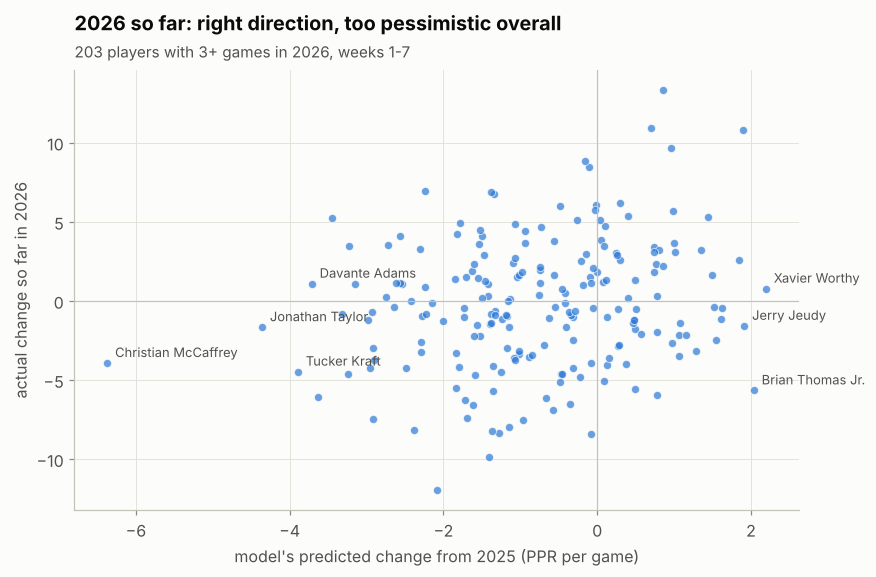

In [7]:
fig, ax = plt.subplots(figsize=(8.5, 5.2))
ax.scatter(check.model_change, check.actual_change, s=28, color=P.BLUE, alpha=0.7, edgecolor=P.SURFACE, linewidth=0.6)
lim = max(check.model_change.abs().max(), 1) * 1.1
ax.axhline(0, color=P.GREY, linewidth=0.8)
ax.axvline(0, color=P.GREY, linewidth=0.8)
for _, r in pd.concat([check.nsmallest(4, "model_change"), check.nlargest(3, "model_change")]).iterrows():
    ax.annotate(r["name"], (r.model_change, r.actual_change), xytext=(5, 4), textcoords="offset points",
                fontsize=8.5, color=P.INK_2)
ax.set_xlabel("model's predicted change from 2025 (PPR per game)")
ax.set_ylabel("actual change so far in 2026")
ax.set_title("2026 so far: right direction, too pessimistic overall", pad=26)
P.subtitle(ax, f"{len(check)} players with 3+ games in 2026, weeks 1-7")
P.save(fig, "15_season_2026_check")

### 2026 projections, top 12 per position (with 2026 so far)

In [8]:
board = check.sort_values("proj_2026", ascending=False).groupby("position").head(12)
board[["position", "name", "team", "age", "ppg", "proj_2026", "ppg_2026", "games_2026"]].sort_values(
    ["position", "proj_2026"], ascending=[True, False]).round(1).rename(
    columns={"ppg": "2025 PPG", "proj_2026": "projected", "ppg_2026": "2026 so far", "games_2026": "games"})

,position,name,team,age,2025 PPG,projected,2026 so far,games
43,QB,Josh Allen,BUF,29.3,22.8,20.2,26.9,6
173,QB,Drake Maye,NE,23.0,20.7,19.4,19.8,7
77,QB,Jalen Hurts,PHI,27.1,18.8,18.1,16.0,5
184,QB,Caleb Williams,CHI,23.8,18.7,18.0,20.9,4
1,QB,Matthew Stafford,LA,37.6,20.6,17.7,17.6,7
92,QB,Trevor Lawrence,JAX,25.9,19.9,17.7,19.0,6
168,QB,Bo Nix,DEN,25.5,17.9,17.6,13.7,7
27,QB,Patrick Mahomes,KC,30.0,20.4,17.5,16.7,6
37,QB,Lamar Jackson,BAL,28.6,16.5,17.3,19.8,4
117,QB,Brock Purdy,SF,25.7,19.7,17.1,20.9,7


## Caveats

* **Survivors only.** About 15% of qualifying players don't get 4+ games the next season (injury, release, retirement).
  The model predicts points per game *if they play*, not the risk that they won't.
* No offseason information: team changes, new coordinators, draft picks, and depth charts are invisible to it.
* Rookies have no previous season, so they aren't projected at all.